In [ ]:
!pip install python-dotenv huggingface-hub llama-index transformers sentence-transformers llama-index-llms-huggingface llama-index-embeddings-huggingface pdfplumber llama-index-llms-openrouter llama-index-retrievers-bm25 tabula-py  jpype1 pystemmer

## 1. Setup & Configuration
In this section, we set up the necessary dependencies, including third-party libraries and API keys.
We also configure the language models (LLMs) and embedding models used throughout the tutorial.

Key Steps:
- Import required Python libraries.
- Load API keys securely from environment variables.
- Initialize the OpenRouter LLMs for both querying and evaluation.
- Set up the HuggingFace embedding model for text representation.
- Apply `nest_asyncio` to handle event loop issues in Jupyter environments.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" # Suppresses TensorFlow warnings
from dotenv import load_dotenv
import Stemmer
import nest_asyncio
import tabula
import pandas as pd
from dotenv import load_dotenv
from llama_index.core import Document
from llama_index.core import (SimpleDirectoryReader, VectorStoreIndex, Settings)
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openrouter import OpenRouter
import asyncio


load_dotenv()  # reads OPENROUTER_API_KEY from a local .env file (never commit it)
api_key = os.getenv("OPENROUTER_API_KEY")
if not api_key:
   raise ValueError("OPENROUTER_API_KEY not found. Copy .env.example to .env and add your key.")


# Initialize OpenRouter LLM
#llm = OpenRouter(api_key=api_key, model="mistralai/mistral-7b-instruct", max_tokens=512, context_window=4096)
llm = OpenRouter(api_key=api_key, model="meta-llama/Llama-3.1-8B-Instruct", max_tokens=512, context_window=4096)
#Judge_llm = OpenRouter(api_key=api_key, model="qwen/qwen-turbo", max_tokens=512, context_window=4096)
Judge_llm = OpenRouter(api_key=api_key, model="openai/gpt-4o-mini", max_tokens=512, context_window=4096)
Settings.llm = llm

# Apply nest_asyncio to fix event loop issues in Jupyter
nest_asyncio.apply()

# Set up embedding model
embed_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embed_model = HuggingFaceEmbedding(model_name=embed_model_name)
Settings.embed_model = embed_model

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

## 2. Document Loading & Preprocessing
Here, we load the syllabus document from a PDF file and process it for retrieval.

Key Steps:
- Read the syllabus PDF and extract its textual content.
- Extract tabular data from the PDF using `tabula`.
- Convert the extracted table data into text format.
- Combine the extracted text and tables into a unified document.
- Define an ingestion pipeline to preprocess text by splitting it into manageable chunks and applying embeddings.


In [3]:
import warnings
import logging
warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)

for name in [
    "llama_index", "httpx", "openai", "urllib3", "tabula", "py4j",
]:
    logging.getLogger(name).setLevel(logging.ERROR)

In [4]:
import re
from llama_index.core import Document
import pdfplumber
import pandas as pd


# Load Course Syllabus Document
#pdf_path = "./Syllabus.pdf"
pdf_path = "./WebMD.pdf"
# documents = SimpleDirectoryReader(input_files=[pdf_path]).load_data()

# Read text page by page (newer LlamaIndex no longer parses PDFs by default)
with pdfplumber.open(pdf_path) as pdf:
    documents = [
        Document(text=page.extract_text() or "", metadata={"file_name": "WebMD.pdf", "page_label": str(i + 1)})
        for i, page in enumerate(pdf.pages)
    ]
documents = [d for d in documents if d.text.strip()]

# Convert table data into an additional Document
# tables = tabula.read_pdf(pdf_path, pages="all", force_subprocess=True)
# table_docs = [df.to_markdown(index=False) for df in tables]
# all_tables_text = "\n\n".join(table_docs)

table_docs = []
with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        for t in page.extract_tables():
            if t and len(t) > 1:
                table_docs.append(pd.DataFrame(t[1:], columns=t[0]).to_markdown(index=False))
all_tables_text = "\n\n".join(table_docs)


document_from_tables = Document(text=all_tables_text)

# Combine original + table doc
documents = documents + [document_from_tables]

# PDF TEXT CLEANING STEP
def clean_pdf_text(t: str) -> str:
    t = re.sub(r"/gid\d+", "", t)
    t = re.sub(r"(\w)-\s*\n(\w)", r"\1\2", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    t = re.sub(r"[ \t]{2,}", " ", t)
    return t.strip()

documents = [
    Document(text=clean_pdf_text(d.text), metadata=d.metadata)
    for d in documents
]

# pipeline with transformations
from llama_index.core.node_parser import SentenceSplitter, TokenTextSplitter
from llama_index.core.ingestion import IngestionPipeline

pipeline = IngestionPipeline(
    transformations=[
        TokenTextSplitter(
            separator="\n\n",
            chunk_size=512,
            chunk_overlap=100
        ),
        embed_model
    ]
)

nodes = pipeline.run(documents=documents)

In [5]:
print("Documents:", len(documents))
for i, d in enumerate(documents):
    print(i, len(d.text), repr(d.text[:80]))

Documents: 10
0 403 '! " #$ !"#$%&!\nCHRONIC MIGRAINE\n!"#$%!&’(#)%’\n#%&’’(%)*+),-%%\n.’/0%1-2,%%\n2*,%3’'
1 1290 'D% ((( )))\n!"#$%&!’(&)#*&%+’’EF?@"?@G #&!’"$#’"$"’%*&$’!!!!!!!!"""###$$$%%%&&&\n6'
2 2360 '(((% )))D\n?">G’’!#"&#!’$"$%#’"$&!"’%*’&$(’!!&)!!!!!!"""####*&$$$%%%%&&&+\n2)"/"4%'
3 2483 '( )\n!"#$%&’!!"#$%&\nSummary of Information About VYEPTI\nImportant Facts about VYE'
4 1183 'Headache Types Overview\nHeadaches are classified by the International Headache S'
5 1987 'D% 4"#$@4%GJ#!@G’’!"#$%&!’(&)#*&%+\nBy Rachel Reiff Ellis\nMOOD DISORDERS NEUROLOG'
6 3831 '@!"#@J"?@%GJ#!@G’’!"#!!$""%##$$&!%%&’&(’’&)!!!!""###*&$$%%%&&+\n(%( ))D\n(*%*)+’.$'
7 3036 'D%\n!"#$%&!’(&)#*&%+’’K6!G@%9"!GF?\n0+&%)’(.’$2%’’\n#HLFE#@"\n!+JBC,&?:>@CB?&GB,>+BC'
8 937 '@!"#@J"?@%GJ#!@G’’!"#$%&!’(&)#*&%+% D\nTHIS CONTENT IS CREATED AND CONTROLLED BY '
9 2149 '| COMPLIMENTARY COPY |\n| TAKE ONE HOME |\n|:---------------------------------|\n| '


In [6]:
import re
from copy import deepcopy

# blacklist
NOISE_PATTERNS = [
    r"\bVYEPTI\b",
    r"\beptinezumab\b",
    r"prescribing information",
    r"all rights reserved",
    r"THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD",
    r"do not receive .* if you are allergic",
]

noise_regex = re.compile("|".join(NOISE_PATTERNS), flags=re.IGNORECASE)

def is_noisy_node(node) -> bool:
    txt = node.get_content() if hasattr(node, "get_content") else str(node)
    return bool(noise_regex.search(txt))

# Filter nodes
nodes_clean = [n for n in nodes if not is_noisy_node(n)]

print("Original nodes:", len(nodes))
print("After noise filtering:", len(nodes_clean))
print("Removed:", len(nodes) - len(nodes_clean))

Original nodes: 17
After noise filtering: 10
Removed: 7


## 3. Indexing & Retrieval
Once the document is processed, we create multiple retrievers for efficient information retrieval.

Key Steps:
- Build a `VectorStoreIndex` from the preprocessed document chunks.
- Implement different retrieval methods:
  - **Base Retriever:** Retrieves the most relevant document chunk.
  - **AutoMerging Retriever:** Aggregates multiple related chunks before returning results.
  - **BM25 Retriever:** Uses term frequency-based ranking (a traditional information retrieval method).
  - **Hybrid Fusion Retriever:** (Task 4)
- Define retrieval hyperparameters, such as similarity threshold and number of top results to return.


In [7]:
from llama_index.core import VectorStoreIndex
from llama_index.retrievers.bm25 import BM25Retriever
from llama_index.core.retrievers import AutoMergingRetriever, QueryFusionRetriever
from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.core.evaluation import RetrieverEvaluator, FaithfulnessEvaluator, RelevancyEvaluator

index_clean = VectorStoreIndex(nodes_clean)

base_retriever_clean = index_clean.as_retriever(similarity_top_k=3)
auto_base_clean = index_clean.as_retriever(similarity_top_k=3)
auto_merging_retriever_clean = AutoMergingRetriever(auto_base_clean, index_clean.storage_context)

bm25_retriever_clean = BM25Retriever.from_defaults(
    nodes=nodes_clean,
    similarity_top_k=2,
    stemmer=Stemmer.Stemmer("english"),
    language="english"
)

vector_retriever_fusion_clean = index_clean.as_retriever(similarity_top_k=8)
bm25_retriever_fusion_clean = BM25Retriever.from_defaults(
    nodes=nodes_clean,
    similarity_top_k=8,
    stemmer=Stemmer.Stemmer("english"),
    language="english"
)

fusion_retriever_clean = QueryFusionRetriever(
    retrievers=[vector_retriever_fusion_clean, bm25_retriever_fusion_clean],
    mode="relative_score",        # weights are only applied in a score-based fusion mode
    retriever_weights=[0.6, 0.4],  # 0.6 vector, 0.4 BM25
    similarity_top_k=5,
    num_queries=4                  # LLM generates 3 extra query variants (multi-query expansion)
)

base_qe_clean = RetrieverQueryEngine.from_args(base_retriever_clean)
auto_qe_clean = RetrieverQueryEngine.from_args(auto_merging_retriever_clean)
bm25_qe_clean = RetrieverQueryEngine.from_args(bm25_retriever_clean)
fusion_qe_clean = RetrieverQueryEngine.from_args(fusion_retriever_clean)

faithfulness_evaluator = FaithfulnessEvaluator(llm=Judge_llm)
relevancy_evaluator = RelevancyEvaluator(llm=Judge_llm)

base_eval_clean = RetrieverEvaluator.from_metric_names(["mrr","hit_rate","precision","recall"], retriever=base_retriever_clean)
auto_eval_clean = RetrieverEvaluator.from_metric_names(["mrr","hit_rate","precision","recall"], retriever=auto_merging_retriever_clean)
bm25_eval_clean = RetrieverEvaluator.from_metric_names(["mrr","hit_rate","precision","recall"], retriever=bm25_retriever_clean)
fusion_eval_clean = RetrieverEvaluator.from_metric_names(["mrr","hit_rate","precision","recall"], retriever=fusion_retriever_clean)

print("Clean retrievers ready.")

Clean retrievers ready.


## 4. Query Engines & Evaluation Setup
In this section, we configure the query engines and set up evaluation metrics to assess retriever performance.

Key Steps:
- Instantiate query engines for each retrieval method to allow direct querying.
- Define evaluation models to measure:
  - **Faithfulness:** Whether the retrieved information is accurate and grounded in the original document.
  - **Relevancy:** Whether the retrieved information is relevant to the query.
- Configure different retriever evaluators to assess retrieval effectiveness using metrics such as:
  - Mean Reciprocal Rank (MRR)
  - Hit Rate
  - Precision
  - Recall


In [8]:
from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.core.evaluation import FaithfulnessEvaluator, RelevancyEvaluator, RetrieverEvaluator

base_qe_engine = RetrieverQueryEngine.from_args(base_retriever_clean)
auto_qe_engine = RetrieverQueryEngine.from_args(auto_merging_retriever_clean)
bm25_qe_engine = RetrieverQueryEngine.from_args(bm25_retriever_clean)
fusion_qe_engine = RetrieverQueryEngine.from_args(fusion_retriever_clean)

faithfulness_evaluator = FaithfulnessEvaluator(llm=Judge_llm)
relevancy_evaluator = RelevancyEvaluator(llm=Judge_llm)

base_retriever_evaluator_clean = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=base_retriever_clean)
auto_retriever_evaluator_clean = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=auto_merging_retriever_clean)
bm25_retriever_evaluator_clean = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=bm25_retriever_clean)
fusion_retriever_evaluator_clean = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=fusion_retriever_clean)

## 5. Preparing Evaluation Questions & Display Functions

In this section, we define a set of evaluation questions to systematically assess the performance of different retrieval methods. Additionally, we create utility functions for displaying results in a structured and readable format.

Key Steps:
- Define a set of test queries (e.g., syllabus-related questions).
- Generate question-context pairs for automated evaluation.

To make evaluation results more interpretable, we define:
- **`displayify_df(df)`**: A helper function to format and display DataFrames neatly in Jupyter notebooks.
- **`display_retriever_eval_results(name, eval_results)`**: Computes and prints key retrieval evaluation metrics.

In [9]:
#from llama_index.core.evaluation import QueryResponseDataset, generate_question_context_pairs, EmbeddingQAFinetuneDataset

import re, json
from dataclasses import dataclass, field, asdict

@dataclass
class QADataset:
    """Minimal QA dataset compatible with RetrieverEvaluator.aevaluate_dataset."""
    queries: dict = field(default_factory=dict)
    corpus: dict = field(default_factory=dict)
    relevant_docs: dict = field(default_factory=dict)
    mode: str = "text"

    def save_json(self, path):
        with open(path, "w") as f:
            json.dump(asdict(self), f, indent=2)


def generate_question_context_pairs(nodes, llm, num_questions_per_chunk=5):
    """Ask the LLM to write questions answerable from each chunk, and link each question to its chunk."""
    data = QADataset()
    for node in nodes:
        text = node.get_content()
        data.corpus[node.node_id] = text
        prompt = (
            f"Context:\n{text}\n\n"
            f"Write {num_questions_per_chunk} question(s) that can be answered only from the context above. "
            "Return one question per line with no numbering."
        )
        lines = [l.strip() for l in str(llm.complete(prompt)).split("\n") if l.strip()]
        questions = [re.sub(r"^[\d\-\.\)\s]+", "", l) for l in lines][:num_questions_per_chunk]
        for i, q in enumerate(questions):
            qid = f"{node.node_id}_{i}"
            data.queries[qid] = q
            data.relevant_docs[qid] = [node.node_id]
    return data

# Use Evaluation Questions
#eval_questions = []
#with open('eval_questions.txt', 'r') as file:
# for line in file:
 # eval_questions.append(line.strip())

# Add more evaluation questions
#eval_questions = [
 # "How can a student request a regrade?",
  # "What topic is covered in Week 3?",
   # "What's happening on Feb 17?"
#]

eval_questions = [
    "What are common symptoms of chronic migraine?",                                          # structured (table)
    "What treatments are mentioned for chronic migraine?",                                    # cross-sectional
    "What are possible triggers or risk factors discussed?",                                  # semantic
    "How do changes in barometric pressure affect migraine?",                                 # keyword-heavy
    "Which conditions often occur alongside chronic migraine?",                               # structured (comorbidities)
    "How long should a patient wait to see if a preventive migraine medication is working?",  # semantic
    "What nondrug options might help with chronic migraine?",                                 # keyword-heavy
    "How does stigma affect the quality of life of people with migraine?",                    # semantic
]

qa_dataset = generate_question_context_pairs(nodes=nodes_clean, llm=llm, num_questions_per_chunk=5)
qa_dataset.save_json("qa_dataset_webmd_new.json")

#qa_dataset = QueryResponseDataset.from_json("./qa_dataset_webmd_new.json")
#qa_dataset = EmbeddingQAFinetuneDataset.from_json("./qa_dataset_webmd_new.json")

# Pretty Display Function
def displayify_df(df):
    """For pretty displaying DataFrame in a notebook."""
    display_df = df.style.set_properties(
        **{
            "inline-size": "300px",
            "overflow-wrap": "break-word",
        }
    )
    display(display_df)

# Helper to display retrieval metrics
def display_retriever_eval_results(name, eval_results):
    """Build a small DataFrame summarizing retrieval metrics across queries."""
    print(f"=== {name} ===")
    metric_dicts = [res.metric_vals_dict for res in eval_results]
    if not metric_dicts:
        print("No retriever metrics found!")
        return
    df = pd.DataFrame(metric_dicts)
    #displayify_df(df)
    print("Mean:\n", df.mean(numeric_only=True), "\n")

## 6. Running Evaluations & Comparing Retrievers
Finally, we conduct retrieval evaluations and compare the effectiveness of different retrieval strategies.

Key Steps:
- Execute retrieval on all retrievers (Base, AutoMerging, BM25, Hybrid Fusion).
- Assess each retriever's faithfulness and relevancy scores.
- Compare retrieval results by averaging the evaluation metrics.
- Display results in tabular format for easy comparison.

This step helps determine which retrieval method performs best for a given dataset.


In [10]:
from llama_index.core.evaluation import RetrieverEvaluator

async def _aevaluate_dataset(self, dataset, **kwargs):
    """Evaluate every query in the QA dataset (removed from newer LlamaIndex, so re-added here)."""
    results = []
    for qid, query in dataset.queries.items():
        results.append(await self.aevaluate(query=query, expected_ids=dataset.relevant_docs[qid]))
    return results

if not hasattr(RetrieverEvaluator, "aevaluate_dataset"):
    RetrieverEvaluator.aevaluate_dataset = _aevaluate_dataset

print("aevaluate_dataset ready.")

aevaluate_dataset ready.


In [11]:
import asyncio
import pandas as pd

async def eval_engine_set(name_prefix, base_qe, auto_qe, bm25_qe, fusion_qe,
                          base_eval, auto_eval, bm25_eval, fusion_eval):
    rows = []

    for q in eval_questions:
        base_resp = base_qe.query(q)
        auto_resp = auto_qe.query(q)
        bm25_resp = bm25_qe.query(q)
        fusion_resp = fusion_qe.query(q)

        rows.append({
            "Set": name_prefix,
            "Query": q,
            "Base Relevancy": relevancy_evaluator.evaluate_response(q, base_resp).score,
            "Auto Relevancy": relevancy_evaluator.evaluate_response(q, auto_resp).score,
            "BM25 Relevancy": relevancy_evaluator.evaluate_response(q, bm25_resp).score,
            "Fusion Relevancy": relevancy_evaluator.evaluate_response(q, fusion_resp).score,
            "Base Faithfulness": faithfulness_evaluator.evaluate_response(query=q, response=base_resp).score,
            "Auto Faithfulness": faithfulness_evaluator.evaluate_response(query=q, response=auto_resp).score,
            "BM25 Faithfulness": faithfulness_evaluator.evaluate_response(query=q, response=bm25_resp).score,
            "Fusion Faithfulness": faithfulness_evaluator.evaluate_response(query=q, response=fusion_resp).score,
        })

    df = pd.DataFrame(rows)

    print(f"\n===== {name_prefix}: Faithfulness (mean) =====")
    print(df[["Base Faithfulness","Auto Faithfulness","BM25 Faithfulness","Fusion Faithfulness"]].mean())

    print(f"\n===== {name_prefix}: Relevancy (mean) =====")
    print(df[["Base Relevancy","Auto Relevancy","BM25 Relevancy","Fusion Relevancy"]].mean())

    base_ds = await base_eval.aevaluate_dataset(qa_dataset)
    auto_ds = await auto_eval.aevaluate_dataset(qa_dataset)
    bm25_ds = await bm25_eval.aevaluate_dataset(qa_dataset)
    fusion_ds = await fusion_eval.aevaluate_dataset(qa_dataset)

    print(f"\n===== {name_prefix}: Retrieval Metrics (dataset) =====")
    display_retriever_eval_results("Base Retriever", base_ds)
    display_retriever_eval_results("Auto-Merging Retriever", auto_ds)
    display_retriever_eval_results("BM25 Retriever", bm25_ds)
    display_retriever_eval_results("Fusion Retriever", fusion_ds)

    return df, base_ds, auto_ds, bm25_ds, fusion_ds

df_before, base_before, auto_before, bm25_before, fusion_before = await eval_engine_set(
    "BEFORE (Task4)",
    base_qe_engine, auto_qe_engine, bm25_qe_engine, fusion_qe_engine,
    base_retriever_evaluator_clean, auto_retriever_evaluator_clean, bm25_retriever_evaluator_clean, fusion_retriever_evaluator_clean
)

# AFTER = clean nodes + weighted fusion + multi-query expansion
df_after, base_after, auto_after, bm25_after, fusion_after = await eval_engine_set(
    "AFTER (Task5 Clean + Query Expansion)",
    base_qe_clean, auto_qe_clean, bm25_qe_clean, fusion_qe_clean,
    base_eval_clean, auto_eval_clean, bm25_eval_clean, fusion_eval_clean
)


===== BEFORE (Task4): Faithfulness (mean) =====
Base Faithfulness      1.0
Auto Faithfulness      1.0
BM25 Faithfulness      1.0
Fusion Faithfulness    1.0
dtype: float64

===== BEFORE (Task4): Relevancy (mean) =====
Base Relevancy      0.875
Auto Relevancy      0.875
BM25 Relevancy      1.000
Fusion Relevancy    1.000
dtype: float64

===== BEFORE (Task4): Retrieval Metrics (dataset) =====
=== Base Retriever ===
Mean:
 mrr          0.800725
hit_rate     0.956522
precision    0.318841
recall       0.956522
dtype: float64 

=== Auto-Merging Retriever ===
Mean:
 mrr          0.800725
hit_rate     0.956522
precision    0.318841
recall       0.956522
dtype: float64 

=== BM25 Retriever ===
Mean:
 mrr          0.750000
hit_rate     0.891304
precision    0.445652
recall       0.891304
dtype: float64 

=== Fusion Retriever ===
Mean:
 mrr          0.864130
hit_rate     0.978261
precision    0.195652
recall       0.978261
dtype: float64 


===== AFTER (Task5 Clean + Query Expansion): Faithfulne

In [12]:
q = "What nondrug options might help with chronic migraine?"
resp = fusion_qe_clean.query(q)

print("ANSWER:", resp.response)
print("\nTOP SOURCES:")
for i, n in enumerate(resp.source_nodes[:3], 1):
    print(f"\n--- source {i} ---")
    print(n.get_content()[:350])

ANSWER: Exercise, changing diet, meditating, prayer, energy work, support groups, herbs, supplements, checking blood for nutrients, looking at mercury and lead levels, and mold exposure.

TOP SOURCES:

--- source 1 ---
cine to prevent future attacks. If your medicine It’s important to give your treatment time to work.
isn’t working, don’t give up. There are more options “Immediate relief doesn’t happen that often in chronic
available today than ever before. migraine,” says Jorge L. Almodóvar-Suárez, MD, division
“With methodical, sustained attempts at treatment, 

--- source 2 ---
the migraine up to my hormones and expected it to be a
single incident. I fully enjoyed my pregnancy. I had my >"G@"!?%#?H%"#G@"!?%@!"#@J"?@G
beautiful baby girl, and I was overjoyed. I’ve tried many things over the years to control my
Unfortunately, migraines came fast and furious back- migraines. I’ve tried exercise, changing my diet,
to-back. I 

--- source 3 ---
disease (IBD) and irritable
have one if you

,mrr,hit_rate,precision,recall
Base (Before),0.800725,0.956522,0.318841,0.956522
Auto (Before),0.800725,0.956522,0.318841,0.956522
BM25 (Before),0.750000,0.891304,0.445652,0.891304
Fusion (Before),0.864130,0.978261,0.195652,0.978261
Base (After),0.800725,0.956522,0.318841,0.956522
Auto (After),0.800725,0.956522,0.318841,0.956522
BM25 (After),0.750000,0.891304,0.445652,0.891304
Fusion (After),0.898551,1.000000,0.200000,1.000000


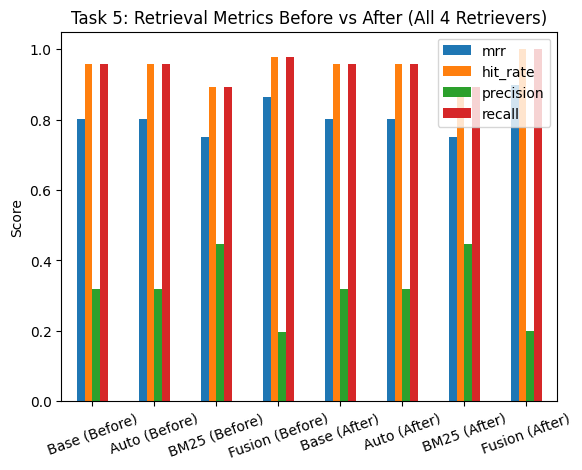

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

def ds_means(eval_results, label):
    metric_dicts = [r.metric_vals_dict for r in eval_results]
    d = pd.DataFrame(metric_dicts).mean(numeric_only=True)
    d.name = label
    return d

# BEFORE summary
summary_before = pd.concat([
    ds_means(base_before, "Base (Before)"),
    ds_means(auto_before, "Auto (Before)"),
    ds_means(bm25_before, "BM25 (Before)"),
    ds_means(fusion_before, "Fusion (Before)"),
], axis=1).T

# AFTER summary
summary_after = pd.concat([
    ds_means(base_after, "Base (After)"),
    ds_means(auto_after, "Auto (After)"),
    ds_means(bm25_after, "BM25 (After)"),
    ds_means(fusion_after, "Fusion (After)"),
], axis=1).T

summary_all = pd.concat([summary_before, summary_after], axis=0)
display(summary_all)

ax = summary_all.plot(kind="bar", rot=20)
ax.set_title("Task 5: Retrieval Metrics Before vs After (All 4 Retrievers)")
ax.set_ylabel("Score")
plt.show()

## 7. Improvement: Cross-Encoder Reranking (Two-Stage Retrieval)

**Why:** in earlier runs, relevant chunks were often retrieved but not ranked near the top, which hurts MRR and answer completeness. First-stage retrievers (embeddings and BM25) score the query and each chunk separately, so they miss fine-grained relevance.

**What:** a two-stage pipeline. Stage 1 uses the weighted hybrid fusion retriever to collect a wide candidate set (top 10). Stage 2 re-scores every (query, chunk) pair jointly with a cross-encoder (`cross-encoder/ms-marco-MiniLM-L-6-v2`) and keeps the best 5.

**Fair comparison:** both variants return 5 chunks, and query expansion is turned off here (`num_queries=1`) so the only difference is the reranker.

In [14]:
from llama_index.core import QueryBundle
from llama_index.core.retrievers import BaseRetriever, QueryFusionRetriever
from llama_index.core.postprocessor import SentenceTransformerRerank
from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.core.evaluation import RetrieverEvaluator

# Stage 2 model: a cross-encoder reads the query and chunk together, so it scores relevance more precisely
reranker = SentenceTransformerRerank(model="cross-encoder/ms-marco-MiniLM-L-6-v2", top_n=5)


class RerankRetriever(BaseRetriever):
    """Retrieve a wide candidate set with any retriever, then reorder it with a reranker."""

    def __init__(self, retriever, reranker):
        self._retriever = retriever
        self._reranker = reranker
        super().__init__()

    def _retrieve(self, query_bundle: QueryBundle):
        candidates = self._retriever.retrieve(query_bundle)
        return self._reranker.postprocess_nodes(candidates, query_bundle=query_bundle)


def make_fusion(top_k):
    """Weighted hybrid retriever (0.6 vector, 0.4 BM25) over the cleaned nodes."""
    return QueryFusionRetriever(
        retrievers=[vector_retriever_fusion_clean, bm25_retriever_fusion_clean],
        mode="relative_score",
        retriever_weights=[0.6, 0.4],
        similarity_top_k=top_k,
        num_queries=1,      # no query expansion, so the comparison isolates the reranker
        use_async=False,
    )


fusion_top5 = make_fusion(top_k=5)                                  # baseline: fusion only
fusion_rerank = RerankRetriever(make_fusion(top_k=10), reranker)    # fusion top 10, reranked to top 5

print("Reranking retriever ready.")


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Reranking retriever ready.


In [15]:
import pandas as pd

METRICS = ["mrr", "hit_rate", "precision", "recall"]


async def retrieval_scores(retriever):
    """Mean MRR, hit rate, precision and recall over the QA dataset."""
    evaluator = RetrieverEvaluator.from_metric_names(METRICS, retriever=retriever)
    results = await evaluator.aevaluate_dataset(qa_dataset)
    return pd.DataFrame([r.metric_vals_dict for r in results]).mean()


rerank_results = pd.DataFrame({
    "Vector": await retrieval_scores(base_retriever_clean),
    "BM25": await retrieval_scores(bm25_retriever_clean),
    "Hybrid fusion": await retrieval_scores(fusion_top5),
    "Hybrid fusion + rerank": await retrieval_scores(fusion_rerank),
}).T.round(3)

print("===== Retrieval metrics: effect of cross-encoder reranking =====")
display(rerank_results)


===== Retrieval metrics: effect of cross-encoder reranking =====


,mrr,hit_rate,precision,recall
Vector,0.801,0.957,0.319,0.957
BM25,0.750,0.891,0.446,0.891
Hybrid fusion,0.826,0.978,0.196,0.978
Hybrid fusion + rerank,0.828,0.935,0.187,0.935


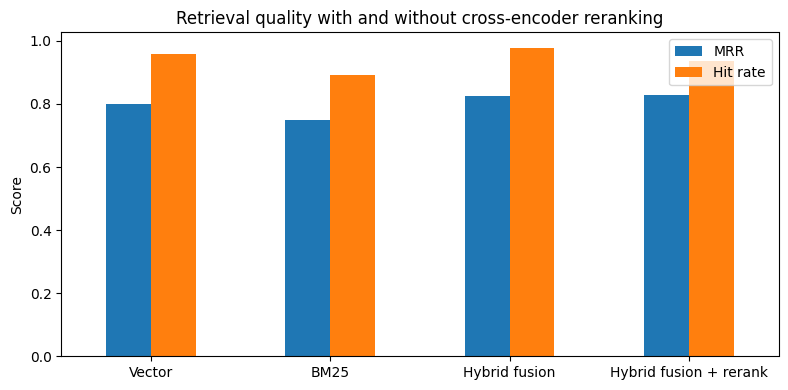

In [16]:
import matplotlib.pyplot as plt
import os
os.makedirs("assets", exist_ok=True)

ax = rerank_results[["mrr", "hit_rate"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Retrieval quality with and without cross-encoder reranking")
ax.set_ylabel("Score")
ax.legend(["MRR", "Hit rate"])
plt.tight_layout()
plt.savefig("assets/reranking_comparison.png", dpi=150)
plt.show()


In [17]:
# Answer quality: does reranking also help the generated answers?
fusion_qe = RetrieverQueryEngine.from_args(fusion_top5)
rerank_qe = RetrieverQueryEngine.from_args(fusion_rerank)

rows = []
for q in eval_questions:
    for name, qe in [("Hybrid fusion", fusion_qe), ("Hybrid fusion + rerank", rerank_qe)]:
        resp = qe.query(q)
        rows.append({
            "Retriever": name,
            "Query": q,
            "Relevancy": relevancy_evaluator.evaluate_response(q, resp).score,
            "Faithfulness": faithfulness_evaluator.evaluate_response(query=q, response=resp).score,
        })

answer_quality = pd.DataFrame(rows).groupby("Retriever")[["Relevancy", "Faithfulness"]].mean().round(3)
print("===== Answer quality: effect of cross-encoder reranking =====")
display(answer_quality)


===== Answer quality: effect of cross-encoder reranking =====


,Relevancy,Faithfulness
Retriever,,
Hybrid fusion,0.875,0.875
Hybrid fusion + rerank,1.000,1.000
